# Détection de fraude dans le mobile money (PaySim)
**Cours d'IA – M2 MIAGE, UFHB – Sujet 5 (classification et réseaux de neurones)**

**En une phrase :** on cherche à repérer, parmi des millions de transactions, les rares fraudes (0,13 %), avec un modèle qui décide assez vite pour agir *pendant* la transaction.

**Le fil du notebook (à suivre dans cet ordre) :**

| Partie | Question à laquelle elle répond |
|---|---|
| 0. Préparation | Quels outils, quelles données ? |
| 1. Exploration | À quoi ressemblent les données et la fraude ? |
| 2. Variables et découpage | Que donne-t-on au modèle, et comment sépare-t-on passé et futur ? |
| 3. Premiers modèles | Un modèle simple suffit-il ? Pourquoi 1,000 est suspect ? |
| 4. Test de solidité | Les scores parfaits sont-ils de la triche (fuite d'information) ? |
| 5. Comparaison des modèles | Qui gagne : anomalies, forêt, AdaBoost, réseau de neurones, SMOTE ? |
| 6. Seuil métier | À partir de quelle probabilité déclenche-t-on une alerte ? |
| 7. Simulation en flux | Est-ce assez rapide pour décider en direct ? |

*Pour tout relancer : Kernel → Restart & Run All (compter 30 à 45 minutes, surtout les forêts).*

## 0. Préparation

### 0.1 Chargement des packages
**Ce qu'on fait :** on importe toutes les bibliothèques une seule fois, ici, en haut du notebook (y compris `os` et `pickle`, qui étaient importés plus bas).

**Rôle de chaque outil :**
- `pandas`, `numpy` : manipuler les tableaux de transactions et calculer.
- `matplotlib` : dessiner les figures du rapport.
- `scikit-learn` : Isolation Forest, Random Forest, AdaBoost et les métriques (rappel, précision, F1, PR-AUC).
- `torch` (PyTorch) : le réseau de neurones.
- `imblearn` (SMOTE) : fabriquer des fraudes artificielles pour rééquilibrer.

In [1]:
import os
import pickle
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.ensemble import IsolationForest, RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             average_precision_score, confusion_matrix)
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

### 0.2 Chargement des données
**Ce qu'on fait :** on lit le fichier PaySim (un fichier CSV placé dans le dossier `data/`) et on affiche sa taille et les premières lignes.

**Comment lire le résultat :** 6 362 620 lignes et 11 colonnes. Chaque ligne est une transaction.
- `step` : l'heure simulée (1 = 1 heure) ; `type` : TRANSFER, CASH_OUT, PAYMENT, CASH_IN, DEBIT ;
- `amount` : montant ; `oldbalanceOrg` / `newbalanceOrig` : solde de l'expéditeur avant / après ;
- `oldbalanceDest` / `newbalanceDest` : solde du destinataire avant / après ;
- `isFraud` : **la vérité** (1 = fraude), c'est l'étiquette qu'on veut prédire ; `isFlaggedFraud` : règle de blocage de la base, qu'on n'utilise pas.

**Notion du cours :** jeu de données étiqueté → apprentissage supervisé.

In [2]:
df = pd.read_csv("../data/PS_20174392719_1491204439457_log.csv")
print(df.shape)
df.head()

(6362620, 11)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


## 1. Exploration des données

### 1.1 Structure et valeurs manquantes
**Ce qu'on fait :** `df.info()` donne le type de chaque colonne ; `isnull().sum()` compte les cases vides.

**Résultat :** zéro valeur manquante dans toutes les colonnes. Donc aucun nettoyage à faire.

**Pourquoi c'est la première étape :** on ne modélise pas sans savoir si les données sont complètes et dans le bon format (nombres, texte).

In [3]:
df.info()
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 534.0 MB


step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

### 1.2 Le déséquilibre des classes
**Ce qu'on fait :** on compte combien de transactions sont normales (0) et frauduleuses (1).

**Résultat :** 6 354 407 normales contre 8 213 fraudes, soit **0,129 %** (environ 1 fraude pour 774 transactions).

**Pourquoi c'est le point central du projet :** un modèle qui répond toujours « pas de fraude » aurait 99,87 % d'accuracy sans rien détecter. L'accuracy est donc inutile ici ; on utilisera le **rappel**, la **précision** et la **PR-AUC**.

**Notion du cours :** classes déséquilibrées, choix des métriques d'évaluation.

In [4]:
counts = df["isFraud"].value_counts()
print(counts)
print(f"Taux de fraude : {df['isFraud'].mean():.4%}")

isFraud
0    6354407
1       8213
Name: count, dtype: int64
Taux de fraude : 0.1291%


### 1.3 Fraude selon le type de transaction
**Ce qu'on fait :** pour chaque type, on compte les transactions, les fraudes (`sum`) et le taux de fraude (`mean`).

**Résultat :** la fraude n'existe **que** dans TRANSFER (4 097 fraudes, 0,77 %) et CASH_OUT (4 116 fraudes, 0,18 %). PAYMENT, CASH_IN et DEBIT n'ont aucune fraude.

**Conséquence :** on ne garde que ces deux types (étape suivante). Les autres types ne peuvent que noyer le modèle.

In [5]:
print(df["type"].value_counts())
print(df.groupby("type")["isFraud"].agg(["sum","mean"]))

type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64
           sum      mean
type                    
CASH_IN      0  0.000000
CASH_OUT  4116  0.001840
DEBIT        0  0.000000
PAYMENT      0  0.000000
TRANSFER  4097  0.007688


### 1.4 Restriction aux deux types à risque
**Ce qu'on fait :** on crée `data`, une copie du tableau limitée à TRANSFER et CASH_OUT. **Tout le reste du notebook travaille sur `data`.**

**Résultat :** 2 770 409 transactions, avec 0,2965 % de fraude (le déséquilibre est un peu moins extrême qu'avant).

In [6]:
data = df[df["type"].isin(["TRANSFER","CASH_OUT"])].copy()
print(data.shape,f"{data['isFraud'].mean():.4%}")

(2770409, 11) 0.2965%


### 1.5 Montants : fraudes contre transactions normales
**Ce qu'on fait :** `describe()` résume la distribution des montants pour chaque classe (moyenne, médiane = 50 %, maximum…).

**Résultat :** médiane de 441 423 pour les fraudes contre 171 034 pour les normales ; moyenne 1,47 M contre 314 k. Le maximum des fraudes vaut exactement 10 000 000 : c'est un **plafond de la simulation**, pas un comportement réel.

**Lecture :** les fraudes sont plus grosses, mais les deux distributions se chevauchent beaucoup. Le montant seul ne suffit pas.

In [7]:
print(data.groupby("isFraud")["amount"].describe())

             count          mean           std   min          25%        50%  \
isFraud                                                                        
0        2762196.0  3.141155e+05  8.771441e+05  0.01   82908.2325  171034.46   
1           8213.0  1.467967e+06  2.404253e+06  0.00  127091.3300  441423.44   

                 75%          max  
isFraud                            
0         305994.185  92445516.64  
1        1517771.480  10000000.00  


### 1.6 Le signal des soldes
**Ce qu'on fait :** on construit deux variables sur le compte de l'expéditeur :
- `errorOrig` = solde avant − montant − solde après. Si tout est cohérent, vaut 0.
- `origEmptied` = 1 si le compte est **vidé** (solde après = 0 alors qu'il y avait de l'argent avant).

**Résultat :** 97,6 % des fraudes vident le compte, contre 42,7 % des transactions normales.

**Lecture :** c'est un fort indice (le fraudeur prend tout), mais pas suffisant seul : 42,7 % de normales, ça fait plus d'un million de transactions.

In [8]:
data["errorOrig"] = data["oldbalanceOrg"]-data["amount"]-data["newbalanceOrig"]

data["origEmptied"] = ((data["newbalanceOrig"]==0) & (data["oldbalanceOrg"]>0)).astype(int)
print(data["origEmptied"].sum())

print(data.groupby("isFraud")[["errorOrig","origEmptied"]].mean())

1188074
             errorOrig  origEmptied
isFraud                            
0       -286803.509954     0.427219
1        -10692.325265     0.975527


### 1.7 Le vidage du compte en détail
**Ce qu'on fait :** on affiche les premières fraudes (solde avant, montant, solde après) et la part de comptes à solde final nul dans chaque classe.

**Résultat :** pour les fraudes, le **montant est égal au solde avant** : le compte est vidé en une seule opération. C'est le **motif central** de PaySim. Il réapparaîtra tout au long du notebook (importance des variables, tests de solidité).

In [9]:
fr = data[data["isFraud"] == 1]
print(fr[["oldbalanceOrg", "amount", "newbalanceOrig"]].head(10))
print((data["newbalanceOrig"] == 0).groupby(data["isFraud"]).mean())
print(data["origEmptied"].sum())

      oldbalanceOrg      amount  newbalanceOrig
2            181.00      181.00             0.0
3            181.00      181.00             0.0
251         2806.00     2806.00             0.0
252         2806.00     2806.00             0.0
680        20128.00    20128.00             0.0
681        20128.00    20128.00             0.0
724            0.00   416001.33             0.0
969      1277212.77  1277212.77             0.0
970      1277212.77  1277212.77             0.0
1115       35063.63    35063.63             0.0
isFraud
0    0.900951
1    0.980519
Name: newbalanceOrig, dtype: float64
1188074


### 1.8 Historique par client : existe-t-il ?
**Ce qu'on fait :** on compte combien de fois chaque expéditeur apparaît.

**Résultat :** 2 768 630 expéditeurs différents pour 2 770 409 transactions : presque chacun n'apparaît qu'**une fois** (3 fois au maximum).

**Conséquence :** on ne peut pas construire de variables de « comportement habituel » (montant moyen d'un client, fréquence). C'est une **limite du jeu de données** à citer dans le rapport.

In [10]:
print (data["nameOrig"].nunique(),"expediteurs unique sur",len(data),"lignes")
print(data["nameOrig"].value_counts().head())

2768630 expediteurs unique sur 2770409 lignes
nameOrig
C2098525306    3
C1902386530    3
C724452879     3
C1101598632    2
C35005848      2
Name: count, dtype: int64


### 1.9 Destinataires et heure
**Ce qu'on fait :** (1) on compte combien de transactions reçoit chaque compte destinataire (`destFreq`), (2) on calcule l'heure de la journée avec `step % 24` (modulo 24 : 25 h devient 1 h).

**Résultats :**
- les destinataires de fraude reçoivent moins de transactions (médiane 3 contre 9) ;
- entre **3 h et 6 h du matin**, 40 à 58 % des transactions sont frauduleuses, contre environ 0,2 % en journée.

**Attention :** l'effet de l'heure vient très probablement de la simulation (peu de transactions normales la nuit). On l'utilise, mais on vérifiera plus tard qu'il n'est pas responsable des bons scores (section 4).

*Remarque : `destFreq` compte aussi les transactions futures du destinataire, donc on ne s'en sert que pour explorer, jamais comme variable du modèle.*

In [11]:
# Destinataires : un même compte reçoit-il plusieurs transactions ?
dest_counts = data["nameDest"].value_counts()
print(dest_counts.head())
data["destFreq"] = data["nameDest"].map(dest_counts)
print(data.groupby("isFraud")["destFreq"].describe())

# Heure de la journée (step = 1 heure simulée)
data["hour"] = data["step"] % 24
print(data.groupby("hour")["isFraud"].mean().round(4))

nameDest
C1286084959    75
C665576141     68
C1360767589    68
C97730845      67
C248609774     64
Name: count, dtype: int64
             count       mean       std  min  25%  50%   75%   max
isFraud                                                           
0        2762196.0  11.599926  8.665446  1.0  5.0  9.0  16.0  75.0
1           8213.0   5.699623  6.832186  1.0  1.0  3.0   8.0  56.0
hour
0     0.0165
1     0.0596
2     0.1935
3     0.4179
4     0.5352
5     0.5791
6     0.3960
7     0.1290
8     0.0357
9     0.0028
10    0.0020
11    0.0016
12    0.0016
13    0.0016
14    0.0018
15    0.0018
16    0.0017
17    0.0017
18    0.0013
19    0.0011
20    0.0014
21    0.0038
22    0.0057
23    0.0085
Name: isFraud, dtype: float64


### 1.10 Les fraudes vont par paires
**Ce qu'on fait :** on associe chaque TRANSFER frauduleux à un CASH_OUT frauduleux de même montant au même `step` (jointure `merge`).

**Résultat :** sur 4 097 TRANSFER frauduleux, **4 078 (99,5 %)** ont un CASH_OUT jumeau. Le schéma est : l'argent est viré vers un compte relais, puis retiré aussitôt.

**Lecture :** c'est un schéma presque systématique dans PaySim. Une fraude réelle serait plus variée : à signaler dans les limites.

In [12]:
fr = data[data["isFraud"] == 1]
t = fr[fr["type"] == "TRANSFER"][["step", "amount"]]
c = fr[fr["type"] == "CASH_OUT"][["step", "amount"]].drop_duplicates()
pairs = t.merge(c, on=["step", "amount"])
print(len(t), "TRANSFER frauduleux |", len(c), "CASH_OUT |", len(pairs), "TRANSFER avec un CASH_OUT de même montant au même step")

4097 TRANSFER frauduleux | 4061 CASH_OUT | 4078 TRANSFER avec un CASH_OUT de même montant au même step


## 2. Variables, découpage temporel et figures

### 2.1 Construction des variables et découpage passé / futur
**Ce qu'on fait, dans l'ordre :**
1. On **trie par `step`** : indispensable, sinon « passé » et « futur » n'ont plus de sens.
2. On crée les variables : `isTransfer` (1 si TRANSFER, 0 si CASH_OUT), `errorDest` (cohérence du solde du destinataire), `hour`, et `destPrior` = nombre de transactions que le destinataire a **déjà reçues avant** celle-ci (`cumcount`). `destPrior` ne regarde que le passé : aucune fuite d'information, calculable en temps réel.
3. **Découpage temporel :** les 80 % premières heures (jusqu'au step 354) servent à **entraîner**, les 20 % restantes à **tester**. Un tirage au hasard mélangerait passé et futur et gonflerait les scores.

**Résultat :** entraînement = 2 217 905 transactions, 3 955 fraudes (0,178 %) ; test = 552 504 transactions, 4 258 fraudes (0,771 %).

**À retenir :** le taux de fraude est 4 fois plus haut dans le test : c'est un **décalage de distribution**. Un modèle au hasard aurait donc une PR-AUC de 0,0077 sur le test : c'est la barre à dépasser.

**Notion du cours :** séparation entraînement / test, sur-apprentissage, fuite de données (*data leakage*).

In [13]:
# Tri chronologique : indispensable pour le split et pour les features "passées"
data = data.sort_values("step").reset_index(drop=True)

# Features
data["isTransfer"] = (data["type"] == "TRANSFER").astype(int)
data["errorDest"] = data["oldbalanceDest"] + data["amount"] - data["newbalanceDest"]
data["hour"] = data["step"] % 24
# Nb de transactions déjà reçues par ce destinataire AVANT celle-ci (pas de fuite)
data["destPrior"] = data.groupby("nameDest").cumcount()

features = ["isTransfer", "amount", "oldbalanceOrg", "newbalanceOrig",
            "oldbalanceDest", "newbalanceDest", "errorOrig", "errorDest",
            "origEmptied", "hour", "destPrior"]

# Split temporel : on entraîne sur le passé, on teste sur le futur
cut = data["step"].quantile(0.8)
train = data[data["step"] <= cut]
test  = data[data["step"] >  cut]

X_train, y_train = train[features], train["isFraud"]
X_test,  y_test  = test[features],  test["isFraud"]

print(f"cut = step {cut:.0f}")
print("train :", X_train.shape, y_train.sum(), "fraudes", f"({y_train.mean():.4%})")
print("test  :", X_test.shape,  y_test.sum(),  "fraudes", f"({y_test.mean():.4%})")

cut = step 354
train : (2217905, 11) 3955 fraudes (0.1783%)
test  : (552504, 11) 4258 fraudes (0.7707%)


### 2.2 Les trois figures du rapport
**Ce qu'on fait :** on dessine et on enregistre dans `figures/` :
1. le déséquilibre des classes (échelle logarithmique, sinon la barre des fraudes est invisible) ;
2. la distribution des montants, fraude contre normal (en log10 du montant) ;
3. le taux de fraude par heure.

**La quatrième figure** (latence) est produite plus bas, dans la simulation en flux (section 7).

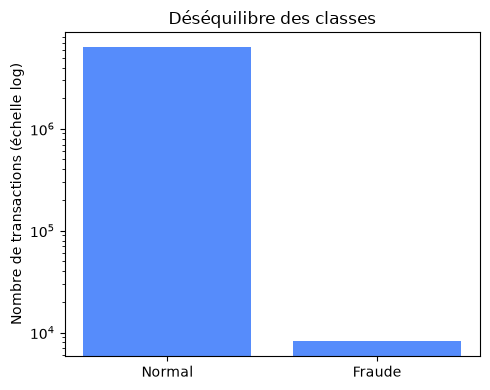

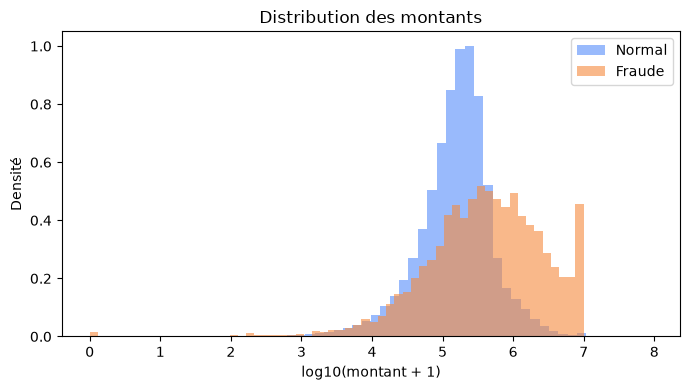

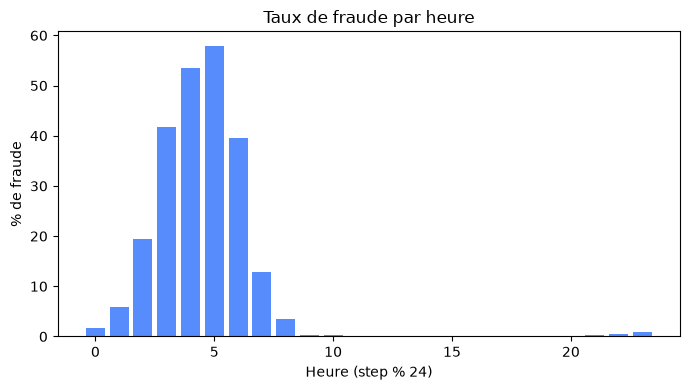

In [14]:
os.makedirs("../figures", exist_ok=True)

# Fig 1 : déséquilibre (échelle log pour voir les fraudes)
fig, ax = plt.subplots(figsize=(5, 4))
counts = df["isFraud"].value_counts()
ax.bar(["Normal", "Fraude"], counts.values)
ax.set_yscale("log")
ax.set_ylabel("Nombre de transactions (échelle log)")
ax.set_title("Déséquilibre des classes")
plt.tight_layout(); plt.savefig("../figures/01_desequilibre.png", dpi=150); plt.show()

# Fig 2 : montants fraude vs normal (log)
fig, ax = plt.subplots(figsize=(7, 4))
for label, g in data.groupby("isFraud"):
    ax.hist(np.log10(g["amount"] + 1), bins=60, alpha=0.6, density=True,
            label="Fraude" if label else "Normal")
ax.set_xlabel("log10(montant + 1)"); ax.set_ylabel("Densité")
ax.set_title("Distribution des montants"); ax.legend()
plt.tight_layout(); plt.savefig("../figures/02_montants.png", dpi=150); plt.show()

# Fig 3 : taux de fraude par heure
rate = data.groupby("hour")["isFraud"].mean() * 100
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(rate.index, rate.values)
ax.set_xlabel("Heure (step % 24)"); ax.set_ylabel("% de fraude")
ax.set_title("Taux de fraude par heure")
plt.tight_layout(); plt.savefig("../figures/03_heure.png", dpi=150); plt.show()

## 3. Premiers modèles (11 variables)

### 3.1 Trois modèles de base
**Ce qu'on fait :** on définit la fonction `evaluer` (affiche rappel, précision, F1, PR-AUC et matrice de confusion), puis on entraîne :
1. **Isolation Forest** (non supervisé, n'utilise pas `isFraud`) : isole les points rares ; `contamination=0.002` = on suppose 0,2 % d'anomalies.
2. **Random Forest** : 100 arbres de décision qui votent ; `class_weight="balanced_subsample"` donne plus de poids aux fraudes ; `min_samples_leaf=5` évite d'apprendre par cœur.
3. **AdaBoost** : 100 petits arbres enchaînés, chacun corrigeant les erreurs du précédent.

**Définitions rapides :**
- **Rappel** = parmi les vraies fraudes, combien on en attrape.
- **Précision** = parmi les alertes, combien sont de vraies fraudes.
- **PR-AUC** = qualité du classement sur tous les seuils (bonne métrique pour classes rares).

**Résultats :** Isolation Forest : rappel 0,028 (120 fraudes trouvées, 4 138 ratées). Random Forest : **1,000 partout** (2 fraudes ratées, 0 fausse alerte). AdaBoost : rappel 0,888.

**Problème :** un score parfait est **suspect**. Les variables les plus importantes du Random Forest : `errorOrig` (43 %), `oldbalanceOrg` (19 %), `origEmptied` (11 %), toutes liées au solde de l'expéditeur. D'où le test de solidité qui suit.

**Notion du cours :** apprentissage supervisé / non supervisé, ensembles d'arbres (bagging, boosting), matrice de confusion.

In [15]:
def evaluer(nom, y_true, y_pred, y_score):
    print(f"\n== {nom} ==")
    print(f"Rappel {recall_score(y_true, y_pred):.3f} | "
          f"Précision {precision_score(y_true, y_pred, zero_division=0):.3f} | "
          f"F1 {f1_score(y_true, y_pred):.3f} | "
          f"PR-AUC {average_precision_score(y_true, y_score):.3f}")
    print(confusion_matrix(y_true, y_pred))

# 1) Non supervisé : Isolation Forest (sans les labels)
iso = IsolationForest(n_estimators=100, contamination=0.002, random_state=42, n_jobs=-1)
iso.fit(X_train)
score_iso = -iso.score_samples(X_test)            # plus haut = plus anormal
pred_iso = (iso.predict(X_test) == -1).astype(int)
evaluer("Isolation Forest", y_test, pred_iso, score_iso)

# 2) Random Forest pondéré
rf = RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample",
                            min_samples_leaf=5, random_state=42, n_jobs=-1)
t = time.time(); rf.fit(X_train, y_train); print(f"\nFit RF : {time.time()-t:.0f}s")
proba_rf = rf.predict_proba(X_test)[:, 1]
evaluer("Random Forest", y_test, (proba_rf >= 0.5).astype(int), proba_rf)

# 3) AdaBoost
ada = AdaBoostClassifier(n_estimators=100, random_state=42)
ada.fit(X_train, y_train)
proba_ada = ada.predict_proba(X_test)[:, 1]
evaluer("AdaBoost", y_test, (proba_ada >= 0.5).astype(int), proba_ada)

# Importance des variables (RF)
print(pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False))


== Isolation Forest ==
Rappel 0.028 | Précision 0.358 | F1 0.052 | PR-AUC 0.095
[[548031    215]
 [  4138    120]]

Fit RF : 109s

== Random Forest ==
Rappel 1.000 | Précision 1.000 | F1 1.000 | PR-AUC 1.000
[[548246      0]
 [     2   4256]]

== AdaBoost ==
Rappel 0.888 | Précision 1.000 | F1 0.941 | PR-AUC 0.999
[[548246      0]
 [   475   3783]]
errorOrig         0.429092
oldbalanceOrg     0.185735
origEmptied       0.114982
newbalanceOrig    0.065066
newbalanceDest    0.063318
amount            0.034989
oldbalanceDest    0.031271
errorDest         0.030778
hour              0.019514
destPrior         0.017879
isTransfer        0.007375
dtype: float64


## 4. Test de solidité : ces 1,000 sont-ils de la triche ?

### 4.1 Uniquement des variables connues avant la transaction
**Ce qu'on fait :** on retire les variables calculées **après** la transaction (`newbalanceOrig`, `newbalanceDest`, `errorOrig`, `errorDest`, `origEmptied`) car en vrai, on ne les connaît pas au moment de décider. On les remplace par deux variables calculables à l'avance :
- `drainsAccount` = 1 si le montant ≥ solde avant (le compte serait vidé) ;
- `amountRatio` = montant / (solde avant + 1).

**Résultat :** toujours rappel = précision = 1,000. Donc **ce n'est pas une fuite d'information post-transaction**. La variable la plus importante est maintenant `amountRatio` (50 %).

In [16]:
# Variables connues AVANT d'autoriser la transaction
data["drainsAccount"] = (data["amount"] >= data["oldbalanceOrg"]).astype(int)
data["amountRatio"] = data["amount"] / (data["oldbalanceOrg"] + 1)

feat_pre = ["isTransfer", "amount", "oldbalanceOrg", "oldbalanceDest",
            "drainsAccount", "amountRatio", "hour", "destPrior"]

# Mêmes lignes qu'avant (le split est temporel donc l'ordre n'a pas changé)
Xtr_pre, Xte_pre = data.loc[X_train.index, feat_pre], data.loc[X_test.index, feat_pre]

rf_pre = RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample",
                                min_samples_leaf=5, random_state=42, n_jobs=-1)
rf_pre.fit(Xtr_pre, y_train)
proba_pre = rf_pre.predict_proba(Xte_pre)[:, 1]
evaluer("RF (variables avant transaction)", y_test, (proba_pre >= 0.5).astype(int), proba_pre)
print(pd.Series(rf_pre.feature_importances_, index=feat_pre).sort_values(ascending=False))


== RF (variables avant transaction) ==
Rappel 1.000 | Précision 1.000 | F1 1.000 | PR-AUC 1.000
[[548246      0]
 [     1   4257]]
amountRatio       0.501766
oldbalanceOrg     0.187839
drainsAccount     0.073188
oldbalanceDest    0.062986
amount            0.060277
destPrior         0.047003
hour              0.038514
isTransfer        0.028428
dtype: float64


### 4.2 Retrait progressif : quatre jeux de difficulté croissante
**Ce qu'on fait :** on affiche d'abord le motif (ratio médian 0,999998 pour les fraudes contre 605 pour les normales), puis on réentraîne le même Random Forest sur quatre jeux de variables :
- **A** : les 11 variables ; **B** : 8 variables d'avant la transaction ; **C** : B sans l'heure ; **D** : 5 variables brutes (sans `amountRatio` ni `drainsAccount`).

**Résultat :** A, B et C donnent 1,000. **Seul D baisse** : rappel 0,769, précision 0,935, PR-AUC 0,914.

**Lecture :** le modèle est parfait tant qu'on lui donne le ratio montant/solde (le motif du vidage). L'heure n'est pas responsable. **On retient D comme scénario difficile** pour comparer honnêtement les modèles, et B comme scénario facile.

*`cols_D` (la liste des 5 variables du jeu D) est définie ici une seule fois et réutilisée plus bas.*

In [17]:
# Variables du scénario difficile D (réutilisées plus bas)
cols_D = ["isTransfer", "amount", "oldbalanceOrg", "oldbalanceDest", "destPrior"]

# Le motif "vidage exact" : où se situe-t-il ?
print(data.groupby("isFraud")[["drainsAccount"]].mean())
print(data.groupby("isFraud")["amountRatio"].describe()[["mean", "50%", "max"]])

# Trois jeux de variables, du plus facile au plus difficile
jeux = {
    "A tout (11 var.)":              features,
    "B avant transaction (8 var.)":  feat_pre,
    "C sans heure (7 var.)":         [f for f in feat_pre if f != "hour"],
    "D brut (5 var.)":               cols_D,
}

resultats = []
for nom, cols in jeux.items():
    m = RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample",
                               min_samples_leaf=5, random_state=42, n_jobs=-1)
    m.fit(data.loc[X_train.index, cols], y_train)
    p = m.predict_proba(data.loc[X_test.index, cols])[:, 1]
    pred = (p >= 0.5).astype(int)
    resultats.append({"jeu": nom,
                      "rappel": recall_score(y_test, pred),
                      "précision": precision_score(y_test, pred, zero_division=0),
                      "PR-AUC": average_precision_score(y_test, p)})

pd.DataFrame(resultats).round(3)

         drainsAccount
isFraud               
0             0.900952
1             0.981736
                  mean         50%          max
isFraud                                        
0        158167.398315  605.538276  92445516.64
1          1161.966671    0.999998   1933920.80


,jeu,rappel,précision,PR-AUC
0,A tout (11 var.),1.000,1.000,1.000
1,B avant transaction (8 var.),1.000,1.000,1.000
2,C sans heure (7 var.),1.000,1.000,1.000
3,D brut (5 var.),0.769,0.935,0.914


## 5. Comparaison complète des modèles (scénarios B et D)

### 5.1 Quatre modèles dans deux scénarios, dont le réseau de neurones
**Ce qu'on fait :** la fonction `run_all` entraîne et évalue, pour un jeu de variables donné, les quatre modèles. `ajouter` range chaque résultat dans le tableau `lignes` et les probabilités dans `probas` (réutilisées plus loin pour le seuil).

**Le réseau de neurones (PyTorch), pas à pas :**
- **Prétraitement :** `log1p` (écrase les écarts d'échelle entre un montant de millions et un indicateur 0/1) puis `StandardScaler` (centrage-réduction).
- **Architecture :** `nn.Sequential` avec `Linear(entrées → 64) → ReLU → Linear(64 → 32) → ReLU → Linear(32 → 1)`. Deux couches cachées ; la sortie est un score converti en probabilité par la sigmoïde.
- **Perte :** `BCEWithLogitsLoss` (entropie croisée binaire) avec `pos_weight` = racine carrée du rapport normales/fraudes : une erreur sur une fraude pèse plus lourd, sans déstabiliser l'entraînement.
- **Entraînement :** optimiseur Adam (taux 0,001), lots de 4 096 transactions, **6 époques**. La perte baisse encore à la fin : le réseau est **sous-entraîné**.

**Résultats (PR-AUC) :**

| Modèle | B facile | D difficile |
|---|---|---|
| Isolation Forest | 0,089 | 0,189 |
| Random Forest | 1,000 | 0,914 |
| AdaBoost | 1,000 | 0,435 |
| Réseau PyTorch | 0,927 | 0,775 |

**Lecture :** le Random Forest domine. AdaBoost a une bonne PR-AUC en D mais un rappel de 0,147 : ses probabilités sont collées autour de 0,5, le seuil par défaut ne lui convient pas. Le réseau est le plus rapide (0,15 ms pour 1 000 transactions) et progresserait avec plus d'époques.

**Choix retenu :** Random Forest, scénario D.

**Notion du cours (Chapitre 3) :** neurone formel, couches, fonctions d'activation (ReLU, sigmoïde), `nn.Linear` / `nn.Sequential`, propagation avant, descente de gradient (Adam), fonction de perte.

In [18]:

torch.manual_seed(42); np.random.seed(42)
probas, lignes = {}, []

def ajouter(scen, modele, p, seuil=0.5, t_inf=None):
    pred = (p >= seuil).astype(int)
    lignes.append({"scénario": scen, "modèle": modele,
                   "rappel": recall_score(y_test, pred),
                   "précision": precision_score(y_test, pred, zero_division=0),
                   "F1": f1_score(y_test, pred),
                   "PR-AUC": average_precision_score(y_test, p),
                   "ms/1000 tr.": t_inf})
    probas[(scen, modele)] = p

def run_all(scen, cols):
    Xtr = data.loc[X_train.index, cols]; Xte = data.loc[X_test.index, cols]

    # Isolation Forest (non supervisé)
    iso = IsolationForest(n_estimators=100, contamination=0.002, random_state=42, n_jobs=-1).fit(Xtr)
    s = -iso.score_samples(Xte); s = (s - s.min()) / (s.max() - s.min())
    ajouter(scen, "Isolation Forest", s, seuil=np.quantile(s, 1 - 0.002))

    # Random Forest
    rf = RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample",
                                min_samples_leaf=5, random_state=42, n_jobs=-1).fit(Xtr, y_train)
    t = time.time(); p = rf.predict_proba(Xte)[:, 1]; ti = (time.time() - t) / len(Xte) * 1e6
    ajouter(scen, "Random Forest", p, t_inf=ti)

    # AdaBoost
    ada = AdaBoostClassifier(n_estimators=100, random_state=42).fit(Xtr, y_train)
    t = time.time(); p = ada.predict_proba(Xte)[:, 1]; ti = (time.time() - t) / len(Xte) * 1e6
    ajouter(scen, "AdaBoost", p, t_inf=ti)

    # Réseau de neurones : log1p (toutes les variables sont >= 0) + standardisation
    sc = StandardScaler().fit(np.log1p(Xtr.values))
    A = torch.tensor(sc.transform(np.log1p(Xtr.values)), dtype=torch.float32)
    B = torch.tensor(sc.transform(np.log1p(Xte.values)), dtype=torch.float32)
    y = torch.tensor(y_train.values, dtype=torch.float32).unsqueeze(1)

    net = nn.Sequential(nn.Linear(A.shape[1], 64), nn.ReLU(),
                        nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 1))
    pw = torch.tensor(((y_train == 0).sum() / (y_train == 1).sum()) ** 0.5)  # racine : plus stable
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pw)
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)

    for ep in range(6):
        perm = torch.randperm(len(A)); tot = 0
        for i in range(0, len(A), 4096):
            idx = perm[i:i + 4096]
            opt.zero_grad(); l = loss_fn(net(A[idx]), y[idx]); l.backward(); opt.step()
            tot += l.item() * len(idx)
        print(f"{scen} | époque {ep+1} | perte {tot/len(A):.4f}")

    net.eval()
    with torch.no_grad():
        t = time.time(); p = torch.sigmoid(net(B)).squeeze().numpy(); ti = (time.time() - t) / len(B) * 1e6
    ajouter(scen, "Réseau PyTorch", p, t_inf=ti)

run_all("B facile", feat_pre)
run_all("D difficile", cols_D)

pd.DataFrame(lignes).round(3)

B facile | époque 1 | perte 0.1086
B facile | époque 2 | perte 0.0377
B facile | époque 3 | perte 0.0316
B facile | époque 4 | perte 0.0285
B facile | époque 5 | perte 0.0267
B facile | époque 6 | perte 0.0246
D difficile | époque 1 | perte 0.1214
D difficile | époque 2 | perte 0.0614
D difficile | époque 3 | perte 0.0579
D difficile | époque 4 | perte 0.0554
D difficile | époque 5 | perte 0.0530
D difficile | époque 6 | perte 0.0505


,scénario,modèle,rappel,précision,F1,PR-AUC,ms/1000 tr.
0,B facile,Isolation Forest,0.058,0.222,0.092,0.089,NaN
1,B facile,Random Forest,1.000,1.000,1.000,1.000,1.159
2,B facile,AdaBoost,0.951,1.000,0.975,1.000,5.581
3,B facile,Réseau PyTorch,0.863,0.842,0.852,0.927,0.132
4,D difficile,Isolation Forest,0.139,0.533,0.220,0.189,NaN
5,D difficile,Random Forest,0.769,0.935,0.844,0.914,1.537
6,D difficile,AdaBoost,0.147,0.983,0.255,0.435,4.956
7,D difficile,Réseau PyTorch,0.731,0.757,0.744,0.775,0.131


### 5.2 Rééchantillonnage : SMOTE contre pondération des classes
**Ce qu'on fait :** SMOTE fabrique des fraudes artificielles en interpolant entre des fraudes voisines, **sur l'entraînement uniquement** (jamais sur le test). On vise 5 % de fraudes par rapport aux normales : 3 955 fraudes réelles deviennent 110 697 exemples. On entraîne ensuite un Random Forest **sans** `class_weight` et on teste sur le test intact.

**Résultat :** rappel 0,816, précision 0,873, F1 0,844, PR-AUC 0,917, à comparer à la pondération : 0,769 / 0,935 / 0,844 / 0,914.

**Lecture :** équivalent. SMOTE attrape plus de fraudes mais fait plus de fausses alertes : il déplace le point de fonctionnement sans améliorer le classement. **On garde la pondération, plus simple et plus rapide.** Le résultat est ajouté au tableau `lignes`, donc il est sauvegardé à l'étape suivante.

**Notion du cours :** rééchantillonnage (sur-échantillonnage), fabrication de données synthétiques.

In [19]:
sm = SMOTE(sampling_strategy=0.05, k_neighbors=5, random_state=42)  # fraudes = 5 % des normales
X_sm, y_sm = sm.fit_resample(data.loc[X_train.index, cols_D], y_train)   # entraînement seulement
print(y_sm.value_counts())

rf_sm = RandomForestClassifier(n_estimators=100, min_samples_leaf=5,
                               random_state=42, n_jobs=-1).fit(X_sm, y_sm)
p_sm = rf_sm.predict_proba(data.loc[X_test.index, cols_D])[:, 1]
ajouter("D difficile", "RF + SMOTE", p_sm)
pd.DataFrame(lignes).tail(1).round(3)

isFraud
0    2213950
1     110697
Name: count, dtype: int64


,scénario,modèle,rappel,précision,F1,PR-AUC,ms/1000 tr.
8,D difficile,RF + SMOTE,0.816,0.873,0.844,0.917,NaN


### 5.3 Sauvegarde des résultats
**Ce qu'on fait :** on enregistre le tableau de tous les résultats (`resultats_modeles.csv`, avec la ligne SMOTE) et les probabilités de chaque modèle (`probas.pkl`). Ainsi, on peut refaire les analyses de seuil sans réentraîner (les forêts prennent plusieurs minutes).

*Cette étape a été déplacée après SMOTE : avant, le fichier CSV n'incluait pas la ligne SMOTE.*

In [20]:
pd.DataFrame(lignes).to_csv("../resultats_modeles.csv", index=False)
pickle.dump(probas, open("../probas.pkl", "wb"))
print("Sauvegardé :", len(lignes), "lignes de résultats")

Sauvegardé : 9 lignes de résultats


## 6. Seuil d'alerte selon les coûts métier

### 6.1 Seuil optimal sur tout le test
**Ce qu'on fait :** un modèle donne une **probabilité** ; le **seuil** décide à partir de quelle probabilité on déclenche l'alerte. Plus il est bas, plus on attrape de fraudes mais plus on fait de fausses alertes. On le choisit en minimisant un **coût** :
- une fraude ratée coûte son **montant** ;
- une fausse alerte coûte un **montant fixe** `c_fp` (appel au client, blocage…), inconnu, donc testé à 1 000, 10 000 et 50 000.

On teste 99 seuils (0,01 à 0,99) et on garde le moins cher.

**Résultats (scénario D) :** sans modèle, les fraudes coûtent 6,70 milliards. Seuil 0,5 avec `c_fp` = 10 000 : 167,8 M. Seuil optimal : `c_fp` 1 000 → seuil 0,02 (coût 18 M) ; 10 000 → 0,08 (64,7 M) ; 50 000 → 0,20 (136,9 M).

**Lecture :** plus une fausse alerte coûte cher, plus le seuil monte. **Le seuil est une décision métier, pas un réglage technique.** Attention : ces chiffres sont optimistes, car le seuil est choisi sur les données mêmes qui servent à l'évaluer.

In [21]:
amount_test = data.loc[X_test.index, "amount"].values
y = y_test.values

def cout(p, seuil, c_fp):
    pred = p >= seuil
    fn = (~pred) & (y == 1)        # fraude ratée : on perd le montant
    fp = pred & (y == 0)           # fausse alerte : coût fixe de traitement
    return amount_test[fn].sum() + c_fp * fp.sum()

seuils = np.linspace(0.01, 0.99, 99)
for scen in ["B facile", "D difficile"]:
    p = probas[(scen, "Random Forest")]
    print(f"\n{scen} | sans modèle : {amount_test[y == 1].sum():,.0f} | seuil 0,5 (c_fp=10 000) : {cout(p, 0.5, 10_000):,.0f}")
    for c_fp in [1_000, 10_000, 50_000]:
        couts = [cout(p, s, c_fp) for s in seuils]
        i = int(np.argmin(couts)); s = seuils[i]; pred = p >= s
        print(f"  coût FP {c_fp:>6} | seuil optimal {s:.2f} | coût {couts[i]:,.0f} | "
              f"rappel {recall_score(y, pred):.3f} | précision {precision_score(y, pred, zero_division=0):.3f}")


B facile | sans modèle : 6,702,594,765 | seuil 0,5 (c_fp=10 000) : 399,045
  coût FP   1000 | seuil optimal 0.20 | coût 10,000 | rappel 1.000 | précision 0.998
  coût FP  10000 | seuil optimal 0.20 | coût 100,000 | rappel 1.000 | précision 0.998
  coût FP  50000 | seuil optimal 0.38 | coût 399,045 | rappel 1.000 | précision 1.000

D difficile | sans modèle : 6,702,594,765 | seuil 0,5 (c_fp=10 000) : 167,757,898
  coût FP   1000 | seuil optimal 0.02 | coût 17,999,497 | rappel 0.979 | précision 0.289
  coût FP  10000 | seuil optimal 0.08 | coût 64,710,458 | rappel 0.933 | précision 0.551
  coût FP  50000 | seuil optimal 0.20 | coût 136,944,411 | rappel 0.855 | précision 0.781


### 6.2 Validation honnête du seuil
**Ce qu'on fait :** on coupe le test en deux moitiés dans le temps. On **choisit** le seuil sur la première moitié, puis on **mesure** le coût sur la seconde, jamais vue pour ce choix.

**Résultats (coût sur la seconde moitié) :**

| Coût fausse alerte | Seuil choisi | Coût au seuil | Coût à 0,5 |
|---|---|---|---|
| 1 000 | 0,04 | 15,3 M | 147,4 M |
| 10 000 | 0,22 | 89,9 M | 148,4 M |
| 50 000 | 0,60 | 171,3 M | 153,2 M |

(sans modèle : 5 804 M)

**Lecture :** le gain tient pour des fausses alertes peu coûteuses (−90 % puis −39 %). Pour 50 000, le seuil appris fait **pire** que 0,5. Le seuil optimal n'est pas stable dans le temps (0,08 sur tout le test, 0,22 sur la première moitié, pour le même coût) : en production, il faudrait le **recalibrer régulièrement**.

In [22]:
steps = data.loc[X_test.index, "step"].values
h1 = steps <= np.median(steps); h2 = ~h1

def cout_m(p, y_, a_, seuil, c_fp):
    pred = p >= seuil
    return a_[(~pred) & (y_ == 1)].sum() + c_fp * (pred & (y_ == 0)).sum()

p = probas[("D difficile", "Random Forest")]
for c_fp in [1_000, 10_000, 50_000]:
    c1 = [cout_m(p[h1], y[h1], amount_test[h1], s, c_fp) for s in seuils]
    s_opt = seuils[int(np.argmin(c1))]
    pred2 = p[h2] >= s_opt
    print(f"c_fp={c_fp:>6} | seuil choisi sur moitié 1 : {s_opt:.2f} | "
          f"coût moitié 2 : {cout_m(p[h2], y[h2], amount_test[h2], s_opt, c_fp):,.0f} "
          f"(seuil 0,5 : {cout_m(p[h2], y[h2], amount_test[h2], 0.5, c_fp):,.0f}, "
          f"sans modèle : {amount_test[h2][y[h2] == 1].sum():,.0f}) | "
          f"rappel {recall_score(y[h2], pred2):.3f} | précision {precision_score(y[h2], pred2, zero_division=0):.3f}")

c_fp=  1000 | seuil choisi sur moitié 1 : 0.04 | coût moitié 2 : 15,294,430 (seuil 0,5 : 147,355,574, sans modèle : 5,803,999,033) | rappel 0.965 | précision 0.537
c_fp= 10000 | seuil choisi sur moitié 1 : 0.22 | coût moitié 2 : 89,900,132 (seuil 0,5 : 148,435,574, sans modèle : 5,803,999,033) | rappel 0.843 | précision 0.877
c_fp= 50000 | seuil choisi sur moitié 1 : 0.60 | coût moitié 2 : 171,308,352 (seuil 0,5 : 153,235,574, sans modèle : 5,803,999,033) | rappel 0.747 | précision 0.972


## 7. Simulation en flux : décide-t-on assez vite ?

**Ce qu'on fait :** on réentraîne le Random Forest du scénario D (les modèles de `run_all` n'avaient pas été conservés, environ 2 minutes), on passe en `n_jobs = 1` (une seule tâche à la fois, comme en inférence réelle), puis on lui envoie **10 000 transactions consécutives du test, une par une**, en chronométrant chaque décision. Seuil utilisé : **0,22** (celui retenu pour `c_fp` = 10 000).

**Résultats :**
- latence moyenne **6,5 ms** (p95 : 8,3 ms ; p99 : 10,6 ms ; max : 14,9 ms), environ 154 transactions par seconde sur un seul cœur ;
- 30 fraudes dans le flux : **29 bloquées, 1 ratée** (6 085) ; 42 alertes au total, dont **13 fausses alertes** ; montant de fraude évité : 42,4 M.

**Lecture :** quelques millisecondes, compatible avec une décision pendant l'autorisation. Les mesures viennent d'un seul poste et ne tiennent pas compte du réseau ni de l'accès aux données du compte en production. La dernière ligne enregistre la quatrième figure (`04_latence.png`).

**Notion du cours :** déploiement / inférence en temps réel, latence.

Latence (ms) : moyenne 7.5 | p95 10.5 | p99 14.9 | max 31.9 | ~133 tr./s
Flux : 10000 tr., 30 fraudes | alertes 42 | vrais positifs 29 | fausses alertes 13 | fraudes ratées 1
Montant fraude évité : 42,404,925 | raté : 6,085


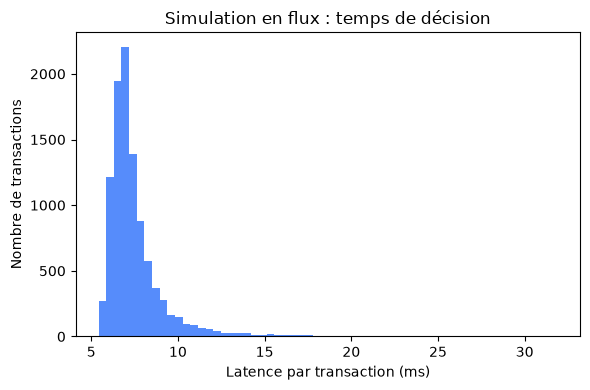

In [23]:
rf_D = RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample",
                              min_samples_leaf=5, random_state=42, n_jobs=-1)
rf_D.fit(data.loc[X_train.index, cols_D].values, y_train)
rf_D.n_jobs = 1                      # inférence une transaction à la fois

SEUIL = 0.22                          # seuil retenu pour un coût de fausse alerte de 10 000
bloc = data.loc[X_test.index].iloc[200_000:210_000]   # 10 000 transactions consécutives
Xs, ys, am = bloc[cols_D].values, bloc["isFraud"].values, bloc["amount"].values

lat, sc = [], []
for i in range(len(Xs)):
    t0 = time.perf_counter()
    sc.append(rf_D.predict_proba(Xs[i:i+1])[0, 1])
    lat.append((time.perf_counter() - t0) * 1000)
lat, sc = np.array(lat), np.array(sc)
alerte = sc >= SEUIL

print(f"Latence (ms) : moyenne {lat.mean():.1f} | p95 {np.percentile(lat,95):.1f} | "
      f"p99 {np.percentile(lat,99):.1f} | max {lat.max():.1f} | ~{1000/lat.mean():.0f} tr./s")
tp = (alerte & (ys == 1)).sum(); fp = (alerte & (ys == 0)).sum(); fn = (~alerte & (ys == 1)).sum()
print(f"Flux : {len(ys)} tr., {ys.sum()} fraudes | alertes {alerte.sum()} | vrais positifs {tp} | "
      f"fausses alertes {fp} | fraudes ratées {fn}")
print(f"Montant fraude évité : {am[alerte & (ys == 1)].sum():,.0f} | raté : {am[~alerte & (ys == 1)].sum():,.0f}")

plt.figure(figsize=(6, 4)); plt.hist(lat, bins=60); plt.xlabel("Latence par transaction (ms)")
plt.ylabel("Nombre de transactions"); plt.title("Simulation en flux : temps de décision")
plt.tight_layout(); plt.savefig("../figures/04_latence.png", dpi=150); plt.show()

## 8. Récapitulatif (à dire en conclusion)
1. L'accuracy ne dit rien quand la fraude est rare : on juge sur rappel, précision, PR-AUC.
2. Des scores parfaits se questionnent : le test de solidité a montré que la fraude PaySim repose sur un motif simple, le vidage du compte.
3. Le seuil est une décision métier, instable dans le temps.
4. Meilleur modèle : Random Forest, scénario D. Sur 10 000 transactions : 29 fraudes sur 30 bloquées, 13 fausses alertes, 6,5 ms par décision.

**Limites à assumer :** données synthétiques ; pas d'historique client ; artefact horaire ; réseau sous-entraîné (6 époques) ; sous-échantillonnage et découpage stratifié non testés.